In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models

In [6]:
df = pd.read_csv("train.csv")
df_test= pd.read_csv("test.csv")

In [7]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df.shape

(33269, 785)

In [9]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33269 entries, 0 to 33268
Columns: 785 entries, label to pixel783
dtypes: float64(320), int64(465)
memory usage: 199.3 MB


In [11]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel779,1
pixel780,1
pixel781,1
pixel782,1


In [12]:
df.dropna(inplace=True)

In [13]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel779,0
pixel780,0
pixel781,0
pixel782,0


In [17]:
#preprocess
X_train = df.drop("label", axis=1).values
y_train = df["label"].values

X_test = df_test.drop("pixel0", axis=1).values
y_test = df_test["pixel0"].values

In [18]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [21]:
# Fix the X_test processing to include all 784 pixel columns (avoid dropping 'pixel0')
# Also handle the NaN values present at the end of df_test
X_test_clean = df_test.fillna(0).values
X_test_scaled = X_test_clean.astype("float32") / 255.0

# Reshape both train and test features into 28x28 images
X_train_img = X_train.reshape((-1, 28, 28, 1))
X_test_img = X_test_scaled.reshape((-1, 28, 28, 1))

print("X_train_img shape:", X_train_img.shape)
print("X_test_img shape:", X_test_img.shape)

X_train_img shape: (33268, 28, 28, 1)
X_test_img shape: (25276, 28, 28, 1)


In [23]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)



In [24]:
Perceptron = Sequential([
    Flatten(input_shape=(28,28,1)),

    Dense(10,activation="softmax")
])

In [25]:
Perceptron.compile(optimizer="sgd",loss="categorical_crossentropy", metrics= ["accuracy"])

In [27]:
history_percp = Perceptron.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)


Epoch 1/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7700 - loss: 0.9688 - val_accuracy: 0.0996 - val_loss: 4.4226
Epoch 2/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8673 - loss: 0.5350 - val_accuracy: 0.0991 - val_loss: 5.2604
Epoch 3/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8803 - loss: 0.4581 - val_accuracy: 0.0999 - val_loss: 5.7281
Epoch 4/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8871 - loss: 0.4204 - val_accuracy: 0.0992 - val_loss: 6.1772
Epoch 5/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8921 - loss: 0.3970 - val_accuracy: 0.0993 - val_loss: 6.4648


In [32]:
acc = Perceptron.evaluate(X_test_img, y_test_cat, verbose=0)[1]


In [33]:
acc

0.09930368512868881

In [34]:
#ANN
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [35]:
ann.compile(optimizer="adam",loss="categorical_crossentropy", metrics= ["accuracy"])

In [36]:
history_ann = ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9101 - loss: 0.3086 - val_accuracy: 0.1006 - val_loss: 9.7935
Epoch 2/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9604 - loss: 0.1311 - val_accuracy: 0.0997 - val_loss: 11.3582
Epoch 3/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9720 - loss: 0.0892 - val_accuracy: 0.0979 - val_loss: 13.3858
Epoch 4/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9798 - loss: 0.0652 - val_accuracy: 0.0992 - val_loss: 14.9481
Epoch 5/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9853 - loss: 0.0478 - val_accuracy: 0.0970 - val_loss: 17.2674


In [37]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [39]:
acc_ann

0.09700901806354523

In [41]:
cnn = Sequential([
    Conv2D(32, kernel_size= (3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [42]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [43]:
history_cnn = cnn.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 43s 40ms/step - accuracy: 0.9166 - loss: 0.2687 - val_accuracy: 0.0970 - val_loss: 13.3338
Epoch 2/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - accuracy: 0.9729 - loss: 0.0907 - val_accuracy: 0.0970 - val_loss: 14.7215
Epoch 3/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 42s 40ms/step - accuracy: 0.9798 - loss: 0.0665 - val_accuracy: 0.0983 - val_loss: 15.0738
Epoch 4/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 41s 39ms/step - accuracy: 0.9841 - loss: 0.0516 - val_accuracy: 0.0973 - val_loss: 17.6678
Epoch 5/5
1040/1040 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - accuracy: 0.9867 - loss: 0.0435 - val_accuracy: 0.0986 - val_loss: 18.2183


In [45]:
acc_cnn = cnn.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [46]:
acc_cnn

0.0986311137676239

In [47]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()


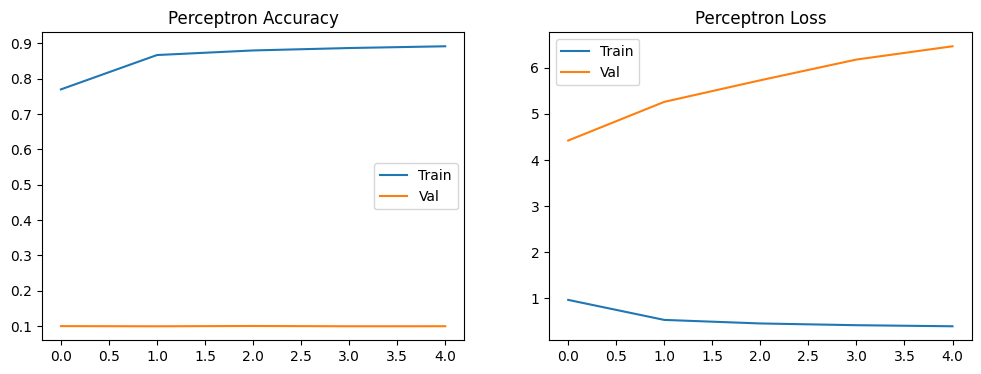

In [48]:

plot_training(history_percp, "Perceptron")

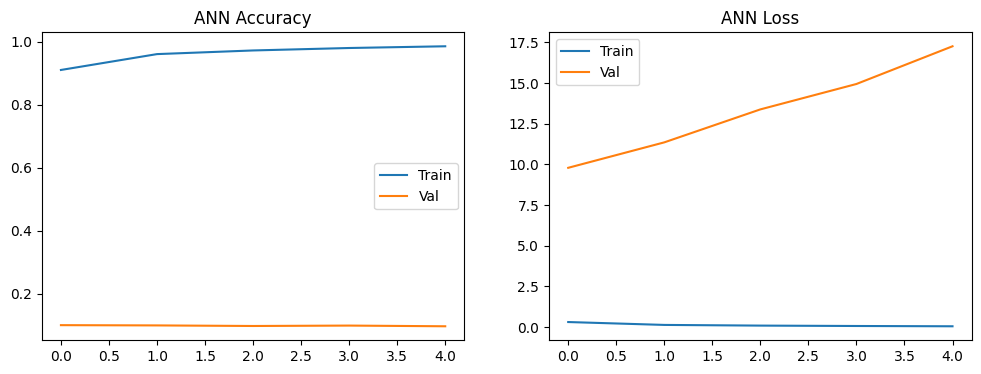

In [49]:



plot_training(history_ann, "ANN")


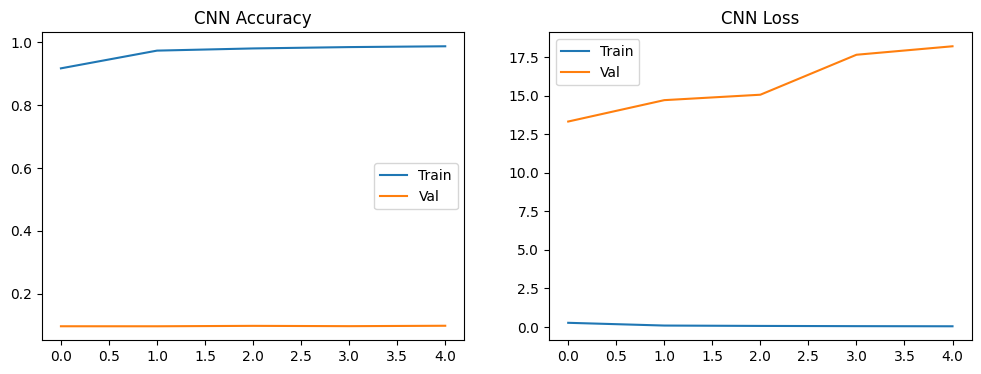

In [50]:

plot_training(history_cnn, "CNN")

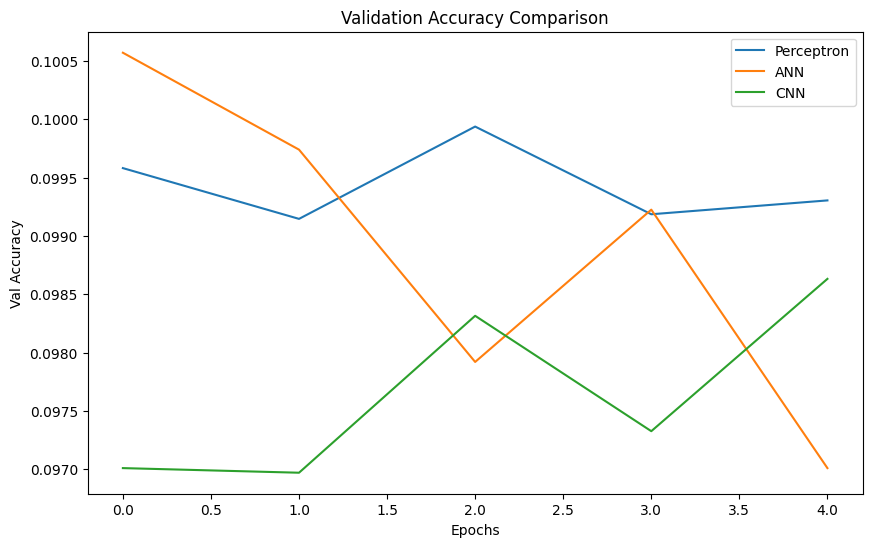

In [51]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [52]:

def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


TypeError: 'History' object is not subscriptable

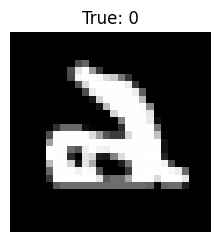

In [59]:

show_side_by_side([Perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, history_cnn , y_test, 5)



In [60]:
y_pred_cnn = np.argmax(cnn.predict(history_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

ValueError: Unrecognized data type: x=<keras.src.callbacks.history.History object at 0x7a19f8e4ae90> (of type <class 'keras.src.callbacks.history.History'>)

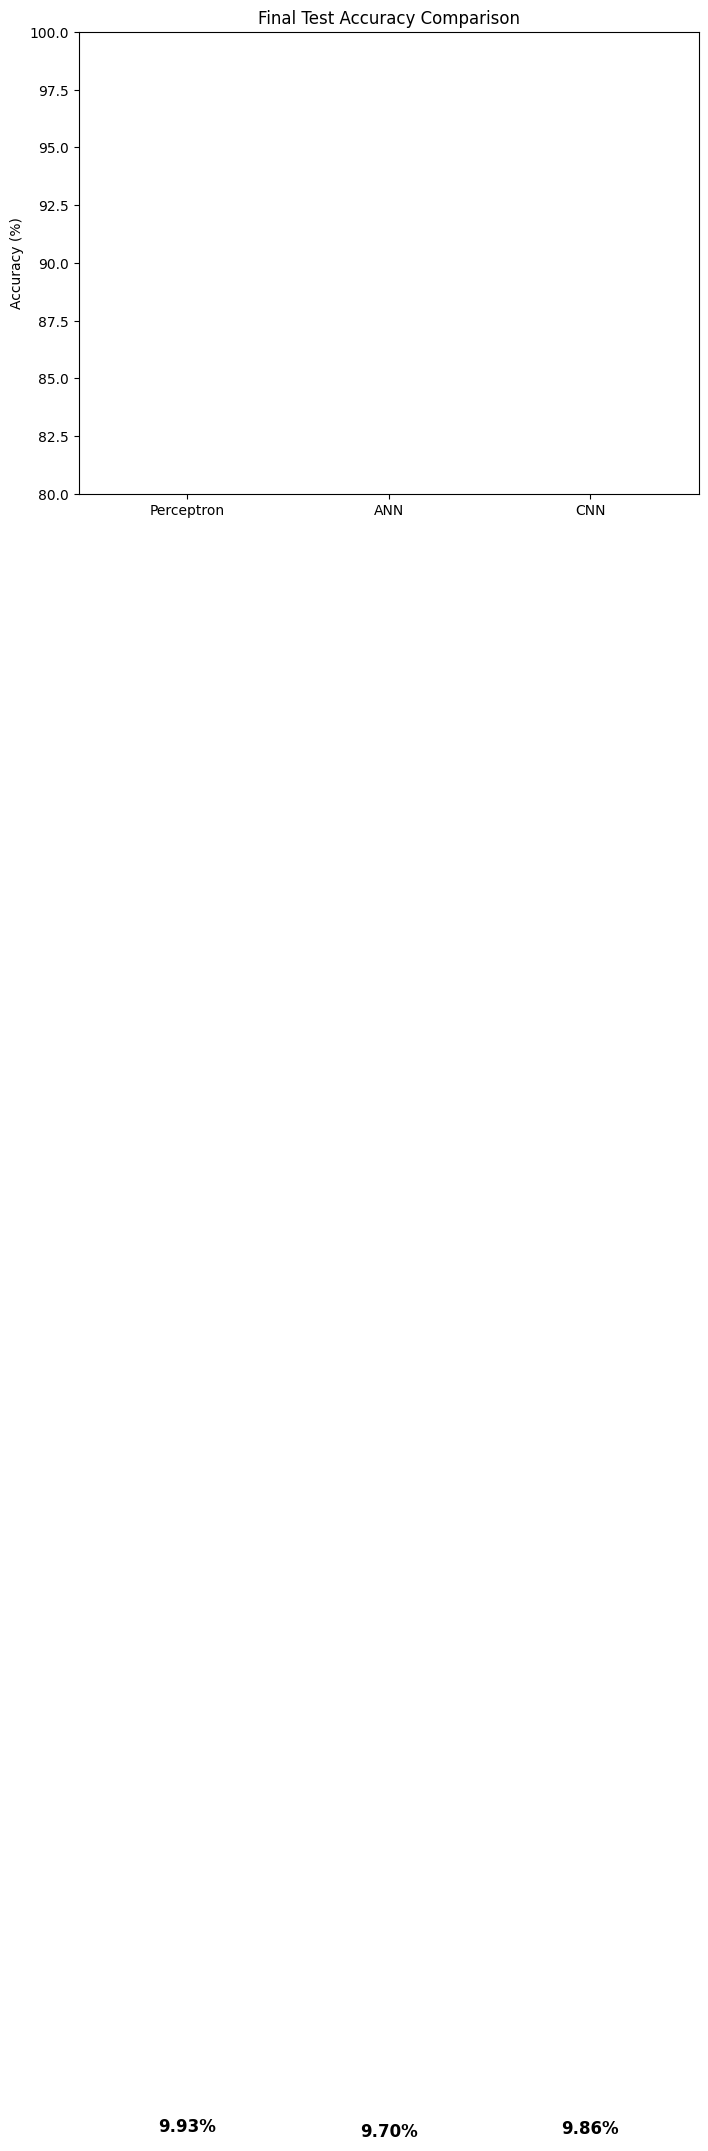

In [61]:
final_accs = [acc_percp*100, acc_ann*100, acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()

